<a href="https://colab.research.google.com/github/nmartini15/UNCC-Machine-Learning/blob/main/Noah_Martini_801294034_Homework5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [106]:
import torch
import matplotlib.pyplot as plt

# Temperature dataset from Lecture 12
t_c = torch.tensor([
    0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
    3.0, -4.0, 6.0, 13.0, 21.0
])

t_u = torch.tensor([
    35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
    33.9, 21.8, 48.4, 60.4, 68.4
])

# Scale the input as done in lecture
t_un = 0.1 * t_u


In [107]:
def model(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()


In [108]:

def training_loop(n_epochs, learning_rate, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):

        # Forward pass
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        # Backward pass
        if params.grad is not None:
            params.grad.zero_()

        loss.backward()

        # Update parameters
        with torch.no_grad():
            params -= learning_rate * params.grad

        # Report loss every 500 epochs
        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss {loss.item():.6f}")

    return params


In [109]:
# Training session 1: Learning rate = 0.1
params = torch.tensor(
    [1.0, 1.0, 0.0],
    requires_grad=True
)

training_loop(
    n_epochs=5000,
    learning_rate=0.1,
    params=params,
    t_u=t_un,
    t_c=t_c
)

print("Final parameters:", params)


Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)


In [110]:
# Training session 2: Learning rate = 0.01
params = torch.tensor(
    [1.0, 1.0, 0.0],
    requires_grad=True
)

training_loop(
    n_epochs=5000,
    learning_rate=0.01,
    params=params,
    t_u=t_un,
    t_c=t_c
)

print("Final parameters:", params)


Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)


In [111]:
# Training session 3: Learning rate = 0.001
params = torch.tensor(
    [1.0, 1.0, 0.0],
    requires_grad=True
)

training_loop(
    n_epochs=5000,
    learning_rate=0.001,
    params=params,
    t_u=t_un,
    t_c=t_c
)

print("Final parameters:", params)


Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)


In [112]:
# Training session 4: Learning rate = 0.0001

params = torch.tensor(
    [1.0, 1.0, 0.0],
    requires_grad=True
)

training_loop(
    n_epochs=5000,
    learning_rate=0.0001,
    params=params,
    t_u=t_un,
    t_c=t_c
)

print("Final parameters:", params)


Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123477
Epoch 2500, Loss 5.377227
Epoch 3000, Loss 4.845285
Epoch 3500, Loss 4.465788
Epoch 4000, Loss 4.194724
Epoch 4500, Loss 4.000802
Epoch 5000, Loss 3.861744
Final parameters: tensor([ 0.5570, -0.8881, -0.8753], requires_grad=True)


In [113]:
# linear model
def linear_model(t_u, w, b):
  return w * t_u + b


In [114]:
def linear_training_loop(n_epochs, learning_rate, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):

        t_p = linear_model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        if params.grad is not None:
            params.grad.zero_()

        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss {loss.item():.6f}")

    return params

# Initialize linear parameters
linear_params = torch.tensor(
    [1.0, 0.0],
    requires_grad=True
)

linear_training_loop(
    n_epochs=5000,
    learning_rate=0.01,
    params=linear_params,
    t_u=t_un,
    t_c=t_c
)

print("Final linear parameters:", linear_params)


Epoch 500, Loss 7.860115
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647
Final linear parameters: tensor([  5.3671, -17.3012], requires_grad=True)


In [115]:
# Best nonlinear parameters from Problem 1.b (.0001 training)
nonlinear_params = torch.tensor([
    0.5570, -0.8881, -0.8753
])

with torch.no_grad():
    linear_predictions = linear_model(t_un, *linear_params)
    nonlinear_predictions = model(t_un, *nonlinear_params)

    linear_loss = loss_fn(linear_predictions, t_c)
    nonlinear_loss = loss_fn(nonlinear_predictions, t_c)

print(f"Linear MSE: {linear_loss.item():.6f}")
print(f"Nonlinear MSE: {nonlinear_loss.item():.6f}")


Linear MSE: 2.927648
Nonlinear MSE: 3.861511


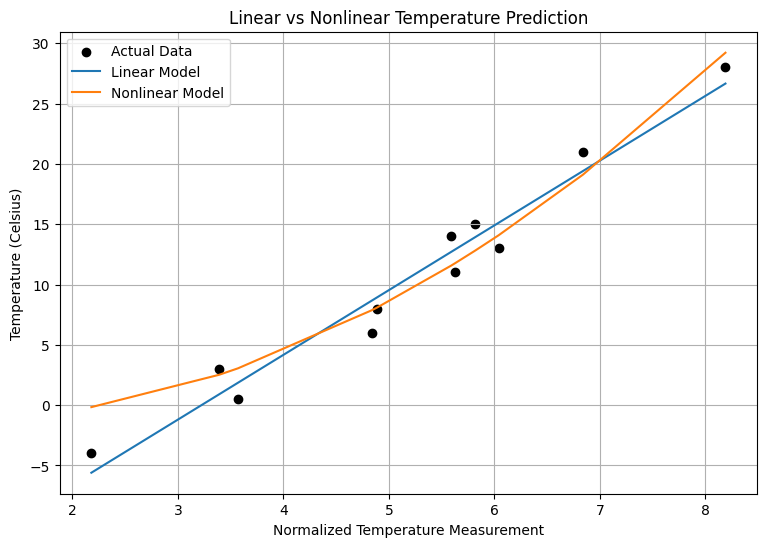

In [116]:
import matplotlib.pyplot as plt

# Sort input values so the curves draw correctly
sorted_indices = torch.argsort(t_un)
x_sorted = t_un[sorted_indices].detach()

with torch.no_grad():
    y_linear = linear_model(x_sorted, *linear_params)
    y_nonlinear = model(x_sorted, *nonlinear_params)

plt.figure(figsize=(9, 6))

plt.scatter(t_un.numpy(), t_c.numpy(),
            label="Actual Data", color="black")

plt.plot(x_sorted.numpy(), y_linear.numpy(),
         label="Linear Model")

plt.plot(x_sorted.numpy(), y_nonlinear.numpy(),
         label="Nonlinear Model")

plt.xlabel("Normalized Temperature Measurement")
plt.ylabel("Temperature (Celsius)")
plt.title("Linear vs Nonlinear Temperature Prediction")
plt.legend()
plt.grid(True)
plt.show()


In [117]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Load housing dataset
df = pd.read_csv("Housing.csv")

print(df.shape)
print(df.columns.tolist())
df.head()


(545, 13)
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [118]:
# Problem 2: Five input features
features_p2 = [
    "area", "bedrooms", "bathrooms",
    "stories", "parking"
]

X = df[features_p2]
y = df["price"]

# 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=15
)

# Normalize input features
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)

# Scale housing prices for stable gradient descent
price_scale = 1_000_000
y_train = y_train.to_numpy() / price_scale
y_val = y_val.to_numpy() / price_scale

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


Training samples: 436
Validation samples: 109


In [119]:
def housing_model(X, w, b):
    return X @ w + b

def housing_loss(predictions, targets):
    return ((predictions - targets) ** 2).mean()

In [120]:
def housing_training_loop(X_train, y_train, X_val, y_val,
                          learning_rate, n_epochs=5000):

    # Initialize parameters
    w = torch.zeros(X_train.shape[1], requires_grad=True)
    b = torch.zeros((), requires_grad=True)

    optimizer = torch.optim.SGD([w, b], lr=learning_rate)

    history = []

    for epoch in range(1, n_epochs + 1):

        # Forward pass
        predictions = housing_model(X_train, w, b)
        loss = housing_loss(predictions, y_train)

        # Backward pass and update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                val_predictions = housing_model(X_val, w, b)
                val_loss = housing_loss(val_predictions, y_val)

                val_r2 = r2_score(
                    y_val.numpy(),
                    val_predictions.numpy()
                )

                history.append([
                    epoch, loss.item(),
                    val_loss.item(), val_r2
                ])

                print(
                    f"Epoch {epoch}: "
                    f"Train MSE={loss.item():.6f}, "
                    f"Val MSE={val_loss.item():.6f}, "
                    f"Val R2={val_r2:.4f}"
                )

    return w.detach().clone(), b.detach().clone(), history

In [121]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]

results_p2 = {}

for lr in learning_rates:
    print(f"\nLearning Rate: {lr}")

    w, b, history = housing_training_loop(
        X_train, y_train, X_val, y_val,
        learning_rate=lr,
        n_epochs=5000
    )

    results_p2[lr] = {
        "weights": w,
        "bias": b,
        "history": history
    }



Learning Rate: 0.1
Epoch 500: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 1000: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 1500: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 2000: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 2500: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 3000: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 3500: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 4000: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 4500: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614
Epoch 5000: Train MSE=1.507383, Val MSE=1.662434, Val R2=0.5614

Learning Rate: 0.01
Epoch 500: Train MSE=1.507384, Val MSE=1.662261, Val R2=0.5614
Epoch 1000: Train MSE=1.507383, Val MSE=1.662437, Val R2=0.5614
Epoch 1500: Train MSE=1.507383, Val MSE=1.662436, Val R2=0.5614
Epoch 2000: Train MSE=1.507383, Val MSE=1.662436, Val R2=0.5614
Epoch 2500: Train MSE=1.507383, Val MSE=1.662436, Val R2=0.5614
E

LR 0.1: Val MSE = 1.662434, R2 = 0.5614
LR 0.01: Val MSE = 1.662436, R2 = 0.5614
LR 0.001: Val MSE = 1.662262, R2 = 0.5614
LR 0.0001: Val MSE = 5.275854, R2 = -0.3920

Best learning rate: 0.001
Weights: tensor([0.7741, 0.1308, 0.5014, 0.5075, 0.2867])
Bias: tensor(4.7440)


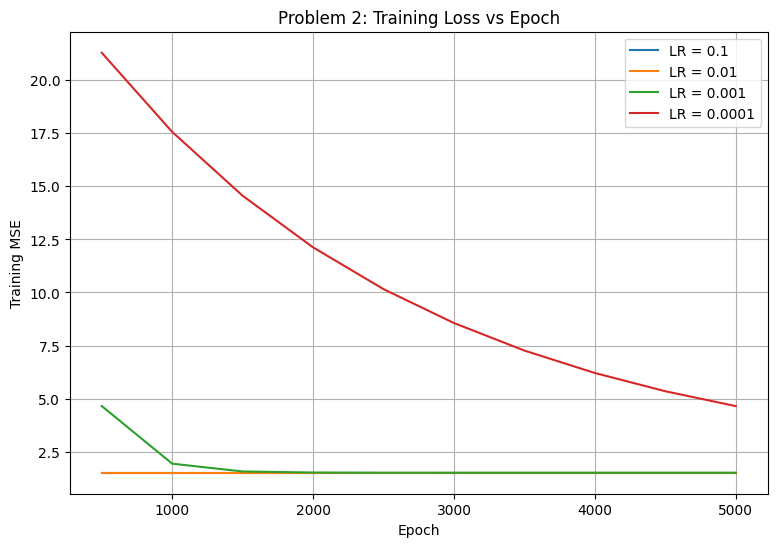

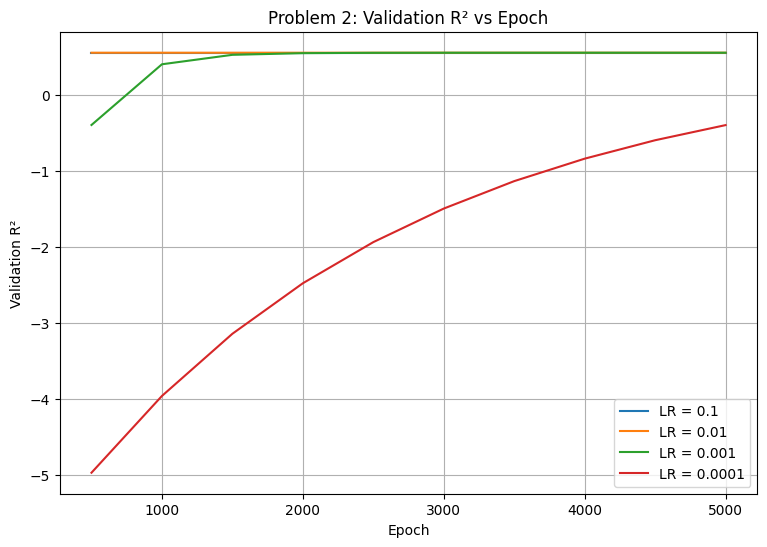

In [130]:
# Compare final validation losses
for lr, result in results_p2.items():
    final = result["history"][-1]
    print(f"LR {lr}: Val MSE = {final[2]:.6f}, R2 = {final[3]:.4f}")

# Select best learning rate based on validation MSE
best_lr_p2 = min(
    results_p2,
    key=lambda lr: results_p2[lr]["history"][-1][2]
)

best_p2 = results_p2[best_lr_p2]

print(f"\nBest learning rate: {best_lr_p2}")
print("Weights:", best_p2["weights"])
print("Bias:", best_p2["bias"])

# Plot training loss for all learning rates
plt.figure(figsize=(9, 6))

for lr, result in results_p2.items():
    history = np.array(result["history"])
    plt.plot(history[:, 0], history[:, 1], label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Problem 2: Training Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

# Plot validation R2
plt.figure(figsize=(9, 6))

for lr, result in results_p2.items():
    history = np.array(result["history"])
    plt.plot(history[:, 0], history[:, 3], label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Validation R²")
plt.title("Problem 2: Validation R² vs Epoch")
plt.legend()
plt.grid(True)
plt.show()


In [134]:
print("Problem 2 Best Parameters:")
for feature, weight in zip(features_p2, best_p2["weights"]):
    print(f"{feature}: {weight.item():.4f}")
print(f"Bias: {best_p2['bias'].item():.4f}")

Problem 2 Best Parameters:
area: 0.7741
bedrooms: 0.1308
bathrooms: 0.5014
stories: 0.5075
parking: 0.2867
Bias: 4.7440


In [123]:
# Problem 3: Use all input features
X_p3 = df.drop(columns=["price"]).copy()
y_p3 = df["price"]

# Convert yes/no columns to binary
binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for col in binary_columns:
    X_p3[col] = X_p3[col].map({"yes": 1, "no": 0})

# Convert furnishing status to two binary columns
X_p3["semi-furnished"] = (
    X_p3["furnishingstatus"] == "semi-furnished"
).astype(int)

X_p3["unfurnished"] = (
    X_p3["furnishingstatus"] == "unfurnished"
).astype(int)

# Remove original text column
X_p3 = X_p3.drop(columns=["furnishingstatus"])

print("Number of features:", X_p3.shape[1])
print("Features:", X_p3.columns.tolist())

# Same 80/20 split as Problem 2
X_train_p3, X_val_p3, y_train_p3, y_val_p3 = train_test_split(
    X_p3, y_p3, test_size=0.2, random_state=15
)

# Normalize features
scaler_p3 = StandardScaler()
X_train_p3 = scaler_p3.fit_transform(X_train_p3)
X_val_p3 = scaler_p3.transform(X_val_p3)

# Scale target values
y_train_p3 = y_train_p3.to_numpy() / 1_000_000
y_val_p3 = y_val_p3.to_numpy() / 1_000_000

# Convert to PyTorch tensors
X_train_p3 = torch.tensor(X_train_p3, dtype=torch.float32)
X_val_p3 = torch.tensor(X_val_p3, dtype=torch.float32)

y_train_p3 = torch.tensor(y_train_p3, dtype=torch.float32)
y_val_p3 = torch.tensor(y_val_p3, dtype=torch.float32)

print("Training samples:", len(X_train_p3))
print("Validation samples:", len(X_val_p3))


Number of features: 13
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'semi-furnished', 'unfurnished']
Number of features: 13
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'semi-furnished', 'unfurnished']
Training samples: 436
Validation samples: 109


In [124]:
# Problem 3: Four training sessions

learning_rates = [0.1, 0.01, 0.001, 0.0001]

results_p3 = {}

for lr in learning_rates:
    print(f"\nLearning Rate: {lr}")

    w, b, history = housing_training_loop(
        X_train_p3,
        y_train_p3,
        X_val_p3,
        y_val_p3,
        learning_rate=lr,
        n_epochs=5000
    )

    results_p3[lr] = {
        "weights": w,
        "bias": b,
        "history": history
    }



Learning Rate: 0.1
Epoch 500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 1000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 1500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 2000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 2500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 3000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 3500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 4000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 4500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 5000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327

Learning Rate: 0.01
Epoch 500: Train MSE=1.059719, Val MSE=1.391069, Val R2=0.6330
Epoch 1000: Train MSE=1.059713, Val MSE=1.392003, Val R2=0.6327
Epoch 1500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 2000: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
Epoch 2500: Train MSE=1.059713, Val MSE=1.392017, Val R2=0.6327
E

In [125]:
# Compare final validation losses
for lr, result in results_p3.items():
    final = result["history"][-1]
    print(f"LR {lr}: Val MSE = {final[2]:.6f}, R2 = {final[3]:.4f}")

# Select best learning rate
best_lr_p3 = min(
    results_p3,
    key=lambda lr: results_p3[lr]["history"][-1][2]
)

best_p3 = results_p3[best_lr_p3]

print(f"\nBest learning rate: {best_lr_p3}")
print("\nBest model parameters:")

for feature, weight in zip(X_p3.columns, best_p3["weights"]):
    print(f"{feature}: {weight.item():.6f}")

print(f"Bias: {best_p3['bias'].item():.6f}")


LR 0.1: Val MSE = 1.392017, R2 = 0.6327
LR 0.01: Val MSE = 1.392017, R2 = 0.6327
LR 0.001: Val MSE = 1.391056, R2 = 0.6330
LR 0.0001: Val MSE = 4.654343, R2 = -0.2280

Best learning rate: 0.001

Best model parameters:
area: 0.568089
bedrooms: 0.105488
bathrooms: 0.410552
stories: 0.426532
mainroad: 0.155797
guestroom: 0.050395
basement: 0.186392
hotwaterheating: 0.176128
airconditioning: 0.450901
parking: 0.190519
prefarea: 0.265845
semi-furnished: -0.006712
unfurnished: -0.204468
Bias: 4.744011


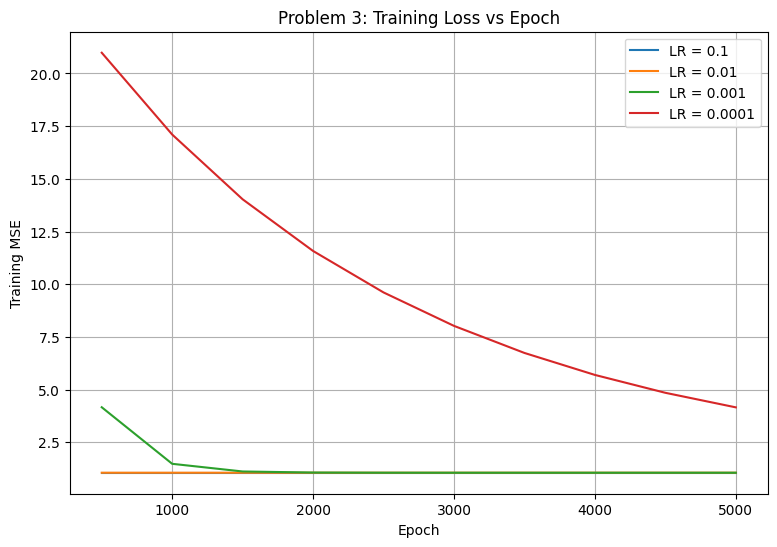

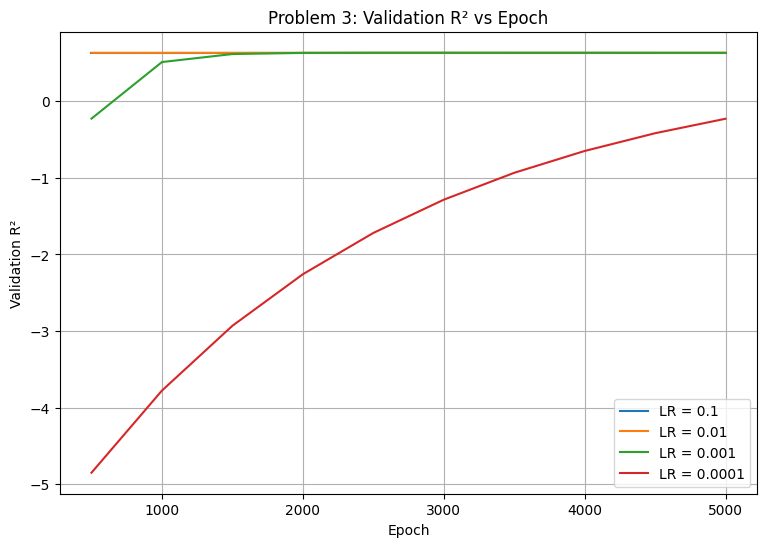

In [126]:
# Training loss comparison
plt.figure(figsize=(9, 6))

for lr, result in results_p3.items():
    history = np.array(result["history"])
    plt.plot(history[:, 0], history[:, 1], label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Problem 3: Training Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

# Validation R2 comparison
plt.figure(figsize=(9, 6))

for lr, result in results_p3.items():
    history = np.array(result["history"])
    plt.plot(history[:, 0], history[:, 3], label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Validation R²")
plt.title("Problem 3: Validation R² vs Epoch")
plt.legend()
plt.grid(True)
plt.show()


In [127]:
p2_val_mse = best_p2["history"][-1][2]
p2_r2 = best_p2["history"][-1][3]

p3_val_mse = best_p3["history"][-1][2]
p3_r2 = best_p3["history"][-1][3]

print("Problem 2 vs Problem 3")
print("-" * 45)

print(f"Problem 2 (5 features):")
print(f"  Validation MSE: {p2_val_mse:.6f}")
print(f"  Validation R²:  {p2_r2:.4f}")

print(f"\nProblem 3 (all features):")
print(f"  Validation MSE: {p3_val_mse:.6f}")
print(f"  Validation R²:  {p3_r2:.4f}")

improvement = (p2_val_mse - p3_val_mse) / p2_val_mse * 100

print(f"\nValidation MSE improvement: {improvement:.2f}%")


Problem 2 vs Problem 3
---------------------------------------------
Problem 2 (5 features):
  Validation MSE: 1.662262
  Validation R²:  0.5614

Problem 3 (all features):
  Validation MSE: 1.391056
  Validation R²:  0.6330

Validation MSE improvement: 16.32%
